**Step 0:** Project Setup
- Imports and display settings

In [58]:
# libraries
import numpy as np
import pandas as pd
import networkx as nx
import requests
import matplotlib.pyplot as plt
from IPython.display import display
import plotly.express as px
from matplotlib.lines import Line2D

# display width
pd.set_option("display.width", 140)

# 1. Data Preparation for Contaminants and Food Layer

**Step 1.1:** Data extraction with API Call/Download Link

- Source: https://zenodo.org
- Download of one file "OCC_CHEMMON2025_BE_2024.ZIP"
- Extract catalogues for unit and substances for member mapping

In [59]:
###### Download of one file ######
# API call: requests.get() fetches the record,.json() turns the answer into a Python dict
rec = requests.get("https://zenodo.org/api/records/22842407").json()

# rec["files"] holds one entry per file. Print name and size and keep the download links in a dict (name -> link).
links = {}
for f in rec["files"]:
    print(f["key"], round(f["size"] / 1e6, 1), "MB") #round MB amount
    links[f["key"]] = f["links"]["self"]

# Load one file: reported in 2025, samples taken in 2024
# read_csv() downloads and loads it into a DataFrame. compression="zip" unpacks it, low_memory=False reads all rows before guessing column types.
df = pd.read_csv(links["OCC_CHEMMON2025_BE_2024.ZIP"], compression="zip", low_memory=False)


OCC_CHEMMON2023_BE_2021.ZIP 0.1 MB
OCC_CHEMMON2023_BE_2020.ZIP 0.0 MB
OCC_CHEMMON2023_BE_2022.ZIP 0.9 MB
OCC_CHEMMON2021_BE_2018.ZIP 0.0 MB
OCC_CHEMMON2022_BE_2019.ZIP 0.0 MB
OCC_CHEMMON2022_BE_2020.ZIP 0.1 MB
OCC_CHEMMON2020_BE_2017.ZIP 0.0 MB
OCC_CHEMMON2022_BE_2021.ZIP 3.3 MB
OCC_CHEMMON2021_BE_2020.ZIP 2.4 MB
OCC_CHEMMON2020_BE_2020.ZIP 0.0 MB
OCC_CHEMMON2021_BE_2019.ZIP 0.1 MB
OCC_CHEMMON2020_BE_2019.ZIP 1.3 MB
OCC_CHEMMON2022_BE_2022.ZIP 0.0 MB
OCC_CHEMMON2021_BE_2021.ZIP 0.0 MB
OCC_CHEMMON2023_BE_2023.ZIP 0.0 MB
OCC_CHEMMON2024_BE_2022.ZIP 0.4 MB
OCC_CHEMMON2024_BE_2023.ZIP 1.4 MB
OCC_CHEMMON2025_BE_2024.ZIP 5.1 MB
OCC_CHEMMON2025_BE_2023.ZIP 0.1 MB
OCC_CHEMMON2025_BE_2022.ZIP 0.1 MB
OCC_CHEMMON2025_BE_2021.ZIP 0.0 MB


In [60]:
###### Download of relevant catalogues for member mapping (estimated loading time is 2-3 min)######
# Download ZIP with EFSA code lists from Zenodo
# "!" runs a terminal command, wget downloads the file, -O sets its name
!wget -q -O catalogues.zip "https://zenodo.org/records/18429596/files/DCF_catalogues.zip?download=1"

# unzip only the three catalogues
# -j drops folder paths, -o overwrites on re-runs, -q keeps it quiet
!unzip -q -o -j catalogues.zip "*UNIT.xlsx" "*PARAM.xlsx" "*MTX.xlsx"

# Show full names
pd.set_option("display.max_colwidth", None)

# read_excel() reads the "term" sheet (one row per code)
# set_index() makes the code the row label, ["termExtendedName"] keeps only the name
units = pd.read_excel("UNIT.xlsx", sheet_name="term").set_index("termCode")["termExtendedName"]
substances = pd.read_excel("PARAM.xlsx", sheet_name="term").set_index("termCode")["termExtendedName"]

# usecols= reads only the code and name columns (performance optimisation)
foods = pd.read_excel("MTX.xlsx", sheet_name="term", usecols=["termCode", "termExtendedName"]).set_index("termCode")["termExtendedName"]

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning:

Workbook contains no default style, apply openpyxl's default



**Step 1.2:** Data Inspection of file "OCC_CHEMMON2025_BE_2024.ZIP"
- Basic stats + features
- Print small snippet of table

In [61]:
# Inspection of table size
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# set_option() shows all rows
pd.set_option("display.max_rows", None)

# one line per column: filled cells (notna + sum), number of distinct values (nunique) and an example from the first row (iloc[0])
overview = pd.DataFrame({
    "filled": df.notna().sum(),
    "unique": df.nunique(),
    "example": df.iloc[0],
})
overview
display(overview)

Rows: 127543
Columns: 215


,filled,unique,example
localOrgCountry,127543,1,N_A
progId_A,127543,3,B1C91BF421FD55731CBE3A4DF8A24CDF
progLegalRef,127543,18,N211A
sampStrategy,127543,3,ST10A
progType,127543,8,K018A
sampMethod,127543,9,N017A
sampler,127543,1,CX02A
sampPoint,127543,21,E152A
progInfo.targetVerif,127543,1,N_A
progInfo.contrFlocks,0,0,NaN


In [62]:
# printing sample of table
from google.colab import data_table
data_table.enable_dataframe_formatter()
df.sample(10, random_state=1) #stops at 20 columns

,localOrgCountry,progId_A,progLegalRef,sampStrategy,progType,sampMethod,sampler,sampPoint,progInfo.targetVerif,progInfo.contrFlocks,...,evalCode,actTakenCode,evalInfo.sampAnAsses,evalInfo.sampTkAsses,evalInfo.sampEventAsses,evalInfo.synTestAsses,evalInfo.resultAssess,evalInfo.conclusion,evalInfo.tseIndexCase,evalInfo.tseNationalCaseId
100027,N_A,B1C91BF421FD55731CBE3A4DF8A24CDF,N379A,ST10A,K005A,N013A,CX02A,E355A,N_A,NaN,...,J037A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
78309,N_A,B1C91BF421FD55731CBE3A4DF8A24CDF,N379A,ST10A,K005A,N011A,CX02A,E500A,N_A,NaN,...,J029A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
59792,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N009A,CX02A,E510A,N_A,NaN,...,J002A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
33587,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N009A,CX02A,E510A,N_A,NaN,...,J029A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
20539,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST30A,K005A,N009A,CX02A,E098A,N_A,NaN,...,J002A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
96197,N_A,B1C91BF421FD55731CBE3A4DF8A24CDF,N379A,ST10A,K018A,N017A,CX02A,E311A,N_A,NaN,...,J037A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
3521,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N014A,CX02A,E351A,N_A,NaN,...,J029A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
12220,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N009A,CX02A,E510A,N_A,NaN,...,J029A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
10241,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N009A,CX02A,E110A,N_A,NaN,...,J002A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A
66484,N_A,4D6AF8D33C2208065B15D12C76D967F4,N027A,ST20A,K005A,N009A,CX02A,E510A,N_A,NaN,...,J002A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A,N_A


**Step 1.3:** Filter relevant columns and show most frequent contaminants and foods

In [63]:
# The columns needed: sample, strategy, date, origin, food, substance and result
keep = [
    "sampId_A", "sampStrategy", "sampY", "sampM", "origCountry",
    "sampMatCode.base.building", "sampMatCode.process", #sampMatCode.base.building will be important for the mapping later on
    "paramCode.base.param", "paramType",
    "resUnit", "resLOQ", "resLOD", "resVal", "resType", "exprResType",
]

# df[keep] picks only these columns, copy() makes a separate table
data = df[keep].copy()
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

# catalogues from data extraction (step 1)
names = {"resUnit": units, "paramCode.base.param": substances}

# count how often each code appears and keep the 15 most frequent codes
for col in ["sampStrategy", "resType", "resUnit", "exprResType", "paramType",
            "paramCode.base.param", "sampMatCode.base.building"]:
    counts = data[col].value_counts().head(15)
    percent = (counts / len(data) * 100).round(1)
    table = pd.DataFrame({"count": counts, "percent": percent})
    # mapping to catalogue members
    if col in names:
        table["name"] = table.index.map(names[col])
    print(table)

Rows: 127543
Columns: 15
              count  percent
sampStrategy                
ST20A         91256     71.5
ST10A         23560     18.5
ST30A         12727     10.0
          count  percent
resType                 
LOQ      114719     89.9
VAL        6798      5.3
CCA        5501      4.3
BIN         377      0.3
CCB         148      0.1
          count  percent                name
resUnit                                     
G061A    100992     79.2  Milligram/kilogram
G050A     19470     15.3  Microgram/kilogram
G076A      5941      4.7       Nanogram/gram
G062A       388      0.3     Milligram/litre
G051A       331      0.3     Microgram/litre
G078A       260      0.2      Nanogram/litre
G015A       109      0.1       Gram/kilogram
G080A        52      0.0       Picogram/gram
              count  percent
exprResType                 
B001A        117595     92.2
N_A            5649      4.4
B003A          4299      3.4
           count  percent
paramType                
P002A   

**Interpretation of findings:**
- **One row per result:** Each row is a single result (one substance in one sample). The network needs one node per substance --> Step 1.4 needs to summarise the results per substance with `groupby()` and `agg()`.
- **Censoring** (`resType`): 89.9% of results are below the limit of quantification (LOQ), only 5.3% are measured values (VAL). <font color="red">**This supports a core assumption: the model has to handle censored values. It still needs enough measured values to learn from.**</font>
- **Sampling** (`sampStrategy`): Only 18.5% of results come from objective sampling (ST10A), 71.5% from selective (ST20A) and 10.0% from suspect sampling (ST30A). Objective samples are taken at random, so they show typical levels. Selective samples are risk-based, so their levels tend to be somewhat higher. They are kept, as otherwise too little data would remain. <font color="red">**Suspect samples are taken because of a specific suspicion, e.g. earlier non-compliance. They overestimate occurrence and are therefore dropped.**</font> (see screenshot below)
- **Substances** (`paramCode.base.param`): The 15 most frequent substances are all pesticides (codes ending in "PPP", names from the PARAM catalogue in Step 1.1). **Pesticides dominate the ranking and hide other substance groups such as contaminants. <font color="red"> Step 1.4 needs to look at the non-pesticide substances separately. The focus (working hypothesis) is on contaminants, because pesticides fall under different laws (pesticides: 396/2005, contaminants: 315/93) and are assessed with different reference values.**</font>
- **Units** (`resUnit`): There are 8 different unit codes (names from the UNIT catalogue in Step 1.1). <font color="red">**Unit codes need to be unified in the transformation process**</font>

**Explanations note for Sampling methods:**
Link: https://efsa.onlinelibrary.wiley.com/doi/pdf/10.2903/j.efsa.2013.3424
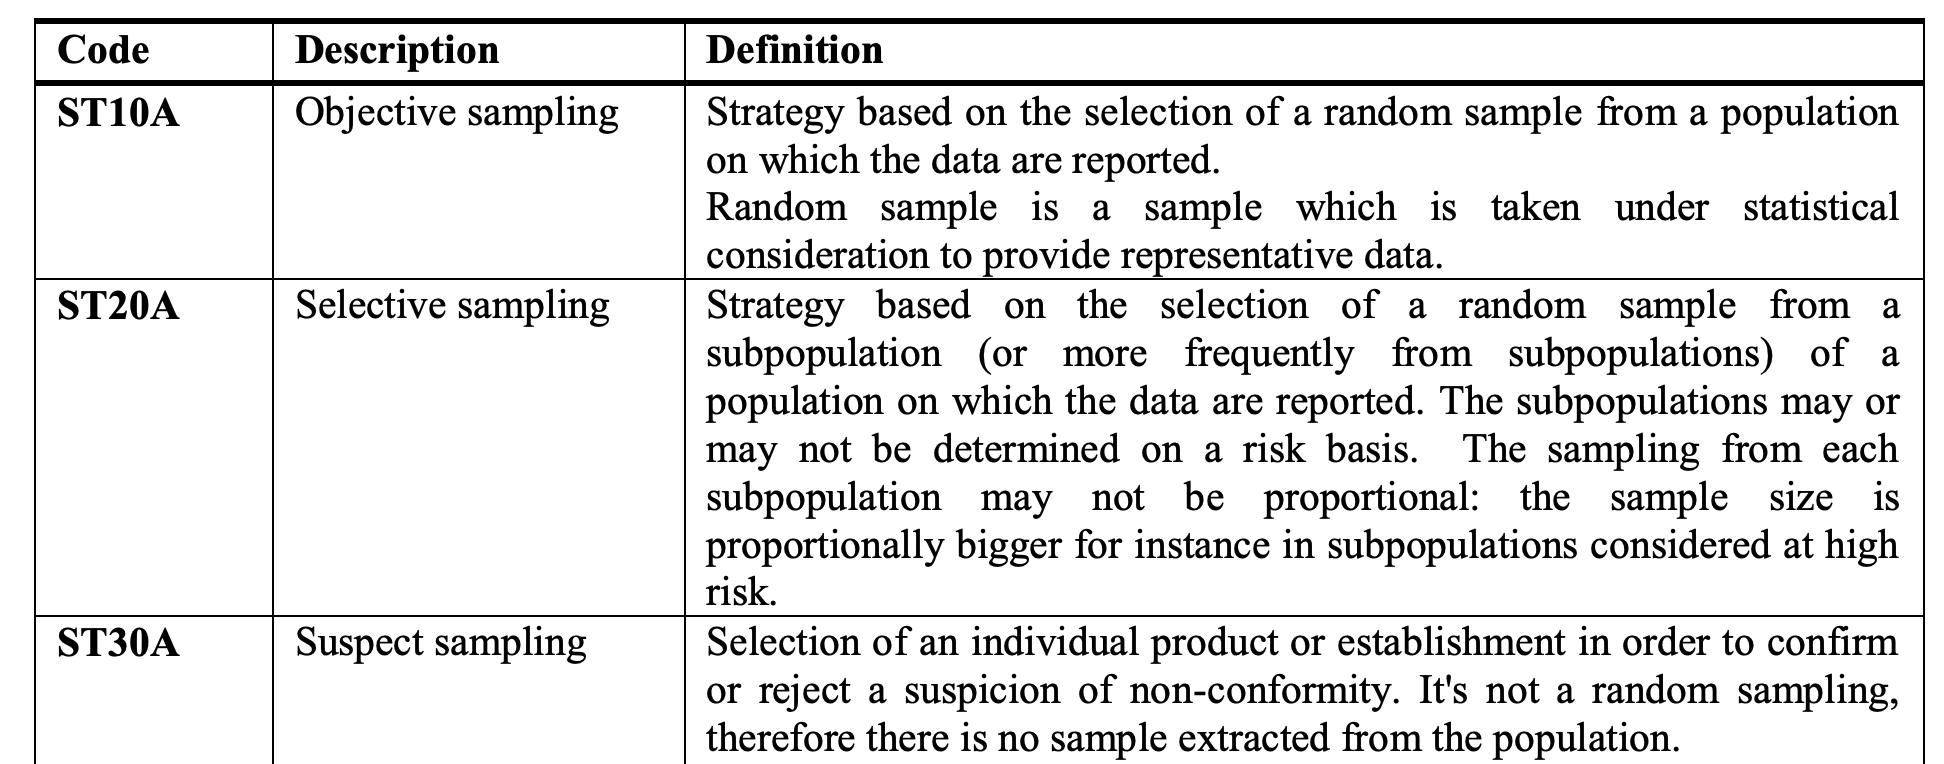

**Relevant EU-regulations for pesticides and contaminants**
- EU regulation for pesticides: https://eur-lex.europa.eu/eli/reg/2005/396/oj
- EU Regulation for contaminants: https://eur-lex.europa.eu/eli/reg/1993/315/oj/eng

**Step 1.4:** Substance overview (non-pesticides)

In [64]:
# contained in data, if "VAL" == "True"
data["measured"] = data["resType"] == "VAL"

# str.endswith() finds pesticide codes (ending PPP), ~ flips the filter, so only the other substances stay
not_pesticide = ~data["paramCode.base.param"].str.endswith("PPP")
# keep only the rows marked True
non_pesticides = data[not_pesticide]

# groupby() + agg()
summary = non_pesticides.groupby("paramCode.base.param")["measured"].agg(results="count", measured="sum")
summary["percent_measured"] = (summary["measured"] / summary["results"] * 100).round(1)
summary["name"] = summary.index.map(substances)

# sort_values()
print(summary.sort_values("results", ascending=False).head(30))

                      results  measured  percent_measured  \
paramCode.base.param                                        
RF-00000449-VET          2548         0               0.0   
RF-00000448-VET          2547         0               0.0   
RF-00003483-PAR          1676         2               0.1   
RF-00010939-PAR          1191         0               0.0   
RF-00000150-CHE           659       278              42.2   
RF-00000150-TOX           650       137              21.1   
RF-00000151-TOX           634        41               6.5   
RF-00000152-TOX           634        27               4.3   
RF-00000153-TOX           634        10               1.6   
RF-00000435-TOX           634       130              20.5   
RF-00000174-CHE           605       109              18.0   
RF-00000134-ORG           571        64              11.2   
RF-00000186-ORG           571       205              35.9   
RF-00000212-ORG           571       104              18.2   
RF-00000169-ORG         

**Step 1.5 Selection of contaminants** (to handle scope of this workbook)

In [65]:
selected = {
    "RF-00000150-CHE": "Cadmium",
    "RF-00000170-CHE": "Mercury (total)",
    "RF-00014549-PAR": "PFAS (sum of 4)",
    "RF-00000015-CHE": "Chlorate",
    "RF-00000174-CHE": "Lead",
    "RF-00000410-ORG": "Acrylamide",
    "RF-00000150-TOX": "Aflatoxin B1",
    "RF-00000148-TOX": "Ochratoxin A",
}

**Step 1.6: Data Transformation**
- Keeping only the scoped contaminants in `selected`
- Removing rows with `sampStrategy` = ST30A (suspect samples)
- Adding a short name for each substance (`substance`)
- Setting one value per result (`value`): the measured value (`resVal`) or, if the result is below the limit, the LOQ (`resLOQ`). `measured` shows which of the two it is
- Checking that no row is left without a value
- Translating the unit codes into names (`unit`) and counting the units per substance, as a basis for converting everything to mg/kg

In [66]:
# condition: isin() checks each code against the list
is_selected = data["paramCode.base.param"].isin(selected.keys())
# keep only the rows marked True
filtered = data[is_selected]

# True for all rows that are not suspect samples (ST30A)
not_suspect = filtered["sampStrategy"] != "ST30A"
# keep only the rows marked True, copy() makes a separate table
filtered = filtered[not_suspect].copy()
print("Rows:", filtered.shape[0])

# map() adds the short name for each substance code
filtered["substance"] = filtered["paramCode.base.param"].map(selected)

# fillna() fills the empty cells in resVal with the LOQ of the same row
filtered["value"] = filtered["resVal"].fillna(filtered["resLOQ"])

# check: isna() marks empty cells with True, sum() counts them (should be 0)
missing = filtered["value"].isna()
print("Rows without a value:", missing.sum())

# map() translates each unit code into its name
filtered["unit"] = filtered["resUnit"].map(units)

# picks the two columns substance and unit
pairs = filtered[["substance", "unit"]]

# value_counts() counts how often each substance-unit pair appears
pair_counts = pairs.value_counts()

# sort_index() sorts list by substance
print(pair_counts.sort_index())

Rows: 3297
Rows without a value: 0
substance        unit              
Acrylamide       Microgram/kilogram    292
Aflatoxin B1     Microgram/kilogram    315
Cadmium          Milligram/kilogram    659
Chlorate         Milligram/kilogram    440
Lead             Milligram/kilogram    605
Mercury (total)  Milligram/kilogram    287
Ochratoxin A     Microgram/kilogram    291
PFAS (sum of 4)  Microgram/kilogram    408
Name: count, dtype: int64


In [67]:
#### Unit conversion ####
# conversion factors to mg/kg, 1 µg/kg = 0.001 mg/kg
factor = {"Milligram/kilogram": 1, "Microgram/kilogram": 0.001}

# map() looks up the factor for each row's unit
row_factor = filtered["unit"].map(factor)

# multiply each value by its factor
filtered["value_mgkg"] = filtered["value"] * row_factor

# check: median()
print(filtered.groupby("substance")["value_mgkg"].median())

# check: count()
print(filtered["exprResType"].value_counts())

substance
Acrylamide         0.104400
Aflatoxin B1       0.000500
Cadmium            0.010000
Chlorate           0.010000
Lead               0.020000
Mercury (total)    0.010000
Ochratoxin A       0.001000
PFAS (sum of 4)    0.000081
Name: value_mgkg, dtype: float64
exprResType
B001A    3297
Name: count, dtype: int64


**Step 1.7:** Overview for food selection
- Translating the food codes into names (`food`), as done for the substances
- Counting the results and the number of different substances per food
- Basis for selecting about 25 foods with enough data

In [68]:
# map() translates each food code into name
filtered["food"] = filtered["sampMatCode.base.building"].map(foods)

# per food: count gives number of results, nunique the number of different substances
food_summary = filtered.groupby("food")["substance"].agg(results="count", substances="nunique")

# overview with sort_values()
print(food_summary.sort_values("results", ascending=False).head(40))

                                                                       results  substances
food                                                                                      
Pig fresh meat                                                             182           3
Pig liver                                                                   80           3
Lettuces (generic)                                                          61           3
Acidity regulator                                                           60           3
Preservative                                                                51           3
Common wheat grain                                                          49           4
Chicken fresh meat                                                          45           4
Pistachios                                                                  45           2
French fries from cut potato                                                45           1

**Interpretation of findings**
- <font color="red">**Keeping foods with at least 25 results**</font> (roughly 30 then)
- <font color="red">**Leaving out food additives**</font>, gelatine and supplements, as they are not regular foods
- <font color="red">**Foods with only one substance stay in** </font> (e.g. French fries for acrylamide), as they are key sources of that substance, so leaving them out would underestimate how much of it people take in

In [69]:
# list for additives
not_food = [
    "Acidity regulator", "Preservative", "Emulsifier", "Raising agents", "Artificial food colour",
    "Food additives other than flavours, colours and artificial sweeteners",
    "Gelatine", "Vitamin only supplements",
]

**Step 1.7 (b):** Food Selection

In [70]:
# condition results >=25
enough_data = food_summary["results"] >= 25

# condition: True for regular foods, ~ flips isin() so the listed ones get False
regular_food = ~food_summary.index.isin(not_food)

# keep the foods where both conditions are True, index gives their names
selected_foods = food_summary[enough_data & regular_food].index
print("Selected foods:", len(selected_foods))

# condition: True for rows with a selected food
is_selected_food = filtered["food"].isin(selected_foods)

# keep only the rows marked True, copy() makes a separate table
occurrence = filtered[is_selected_food].copy()
print("Rows:", occurrence.shape[0])

# check: results and measured values per substance
print(occurrence.groupby("substance")["measured"].agg(results="count", measured="sum"))

Selected foods: 30
Rows: 1245
                 results  measured
substance                         
Acrylamide            99        74
Aflatoxin B1          89         2
Cadmium              254       119
Chlorate             154        48
Lead                 265        43
Mercury (total)       56        43
Ochratoxin A          91         9
PFAS (sum of 4)      237        99


In [71]:
# nrows=0 reads only the header, so it can be seen which columns MTX has (e.g. the FoodEx2 levels)
print(pd.read_excel("MTX.xlsx", sheet_name="term", nrows=0).columns.tolist())

['termCode', 'termExtendedName', 'termShortName', 'termScopeNote', 'version', 'lastUpdate', 'validFrom', 'validTo', 'status', 'deprecated', 'scientificNames', 'commonNames', 'allFacets', 'ISSCAAP', 'taxonomicCode', 'alpha3Code', 'GEMSCode', 'matrixCode', 'LangualCode', 'foodexOldCode', 'implicitFacets', 'detailLevel', 'termType', 'prodTreat', 'prodMeth', 'prodPack', 'EuringsCode', 'IFNCode', 'EUFeedReg', 'EPPOCode', 'VectorNetCode', 'ADDFOODCode', 'masterFlag', 'masterParentCode', 'masterOrder', 'masterReportable', 'masterHierarchyCode', 'reportFlag', 'reportParentCode', 'reportOrder', 'reportReportable', 'reportHierarchyCode', 'pestFlag', 'pestParentCode', 'pestOrder', 'pestReportable', 'pestHierarchyCode', 'biomoFlag', 'biomoParentCode', 'biomoOrder', 'biomoReportable', 'biomoHierarchyCode', 'feedFlag', 'feedParentCode', 'feedOrder', 'feedReportable', 'feedHierarchyCode', 'expoFlag', 'expoParentCode', 'expoOrder', 'expoReportable', 'expoHierarchyCode', 'vetdrugFlag', 'vetdrugParentCo

# 2. Data Preparation for Network Edges and consumer layer (based on consumption data)

**Step 2.1:** Data Inspection
- Selected table: FoodEx2 Level 4 (Link: https://www.efsa.europa.eu/en/microstrategy/foodex2-level-4)
- Relevant columns:
  - `Survey's country` (filter for Belgium)
  - `Survey start year` (filter for 2014, one survey left)
  - `Survey name`
  - `Population Group (L2)` (will be consumer nodes)
  - `Number of subjects` (participants per population group)
  - `Exposure hierarchy (L1)`, `Exposure hierarchy (L2)`,`Exposure hierarchy (L3)`, `Exposure hierarchy (L4)`: FoodEx2 food groups, used to link consumption to the food nodes,
  - `Mean` edge weight from food to population group, mean daily consumption in g/kg bw per day across all subjects

**Assumptions (consumption data)**
- **Chronic consumption:** <font color="red">All eight substances are assessed for long-term exposure (TWI, TDI or BMDL), so long-term average consumption is used</font>. Acute single-day consumption would be compared with an acute reference dose (ARfD), which matters more for pesticides.
- **g/kg body weight per day, all subjects:** Reference values are set per kg body weight, <font color="red">and children eat more per kg than adults. Averages over all subjects, including non-consumers, describe a whole population group</font>; "consumers only" would overstate intake for rarely eaten foods such as mussels.
- FoodEx2 Level 4, no split by gender: <font color="red">Level 4 might balance detail and data availability</font>. Reasoning: A split by gender (e.g. women of childbearing age for mercury and lead) is a possible extension but would roughly halve the sample per group (outlook for future development). <font color="red">**Observed problem:**</font> Occurrence and consumption data describe foods at different FoodEx2 levels (e.g. "Strawberries" vs. "Strawberries and similar-"), so only 9 of the 30 selected foods match by name and the rest are linked through their Level 4 group.

In [72]:
# load data from EFSA, header=2 takes the column names from the third row
file_path = "/content/Foodex 2 L4 dashboard.xlsx"
df = pd.read_excel(file_path, header=2)

# condition: True for Belgian rows
is_belgium = df["Survey's country"] == "Belgium"

# keep only the rows marked True
filtered_df = df[is_belgium]

# overview stats
print(f"Original length: {len(df)}")
print(f"Filtered length (Belgium): {len(filtered_df)}")
print(filtered_df["Survey start year"].value_counts()) #number of rows per survey

# show table
display(filtered_df.head(10))

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning:

Workbook contains no default style, apply openpyxl's default



Original length: 77085
Filtered length (Belgium): 3703
Survey start year
2004    1754
2014    1462
2002     487
Name: count, dtype: int64


,Survey's country,Survey start year,Survey name,Population Group (L2),Exposure hierarchy (L1),Exposure hierarchy (L2),Exposure hierarchy (L3),Exposure hierarchy (L4),Number of subjects,Number of consumers,Mean,Standard Deviation,5th percentile,10th percentile,Median,95th percentile,97.5th percentile,99th percentile,Comment
2805,Belgium,2002,Regional Flanders,Other children,Alcoholic beverages,Beer and beer-like beverage,Beer,Beer,625,10,0.019523,0.228829,0.0,0.0,0.0,0.000000,0.000000,0.368800,NaN
2806,Belgium,2002,Regional Flanders,Other children,Alcoholic beverages,Beer and beer-like beverage,Beer,Lager beer,625,2,0.013428,0.308919,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN
2807,Belgium,2002,Regional Flanders,Other children,Alcoholic beverages,Wine and wine-like drinks,Wine,"Wine, red",625,4,0.000904,0.012926,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN
2808,Belgium,2002,Regional Flanders,Other children,Alcoholic beverages,Wine and wine-like drinks,Wine,"Wine, white",625,3,0.001036,0.015038,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN
2809,Belgium,2002,Regional Flanders,Other children,"Amphibians, reptiles, and terrestrial invertebrates",Terrestrial invertebrates,Snails,"Snail, roman",625,1,0.001536,0.038400,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN
2810,Belgium,2002,Regional Flanders,Other children,Animal and vegetable fats and oils and primary derivatives thereof,Animal and vegetable fats/oils,"Vegetable fats and oils, edible",Olive oils,625,73,0.010797,0.044665,0.0,0.0,0.0,0.069444,0.135894,0.261510,NaN
2811,Belgium,2002,Regional Flanders,Other children,Animal and vegetable fats and oils and primary derivatives thereof,Animal and vegetable fats/oils,"Vegetable fats and oils, edible",Seed oils,625,20,0.003636,0.028018,0.0,0.0,0.0,0.000000,0.046503,0.088189,NaN
2812,Belgium,2002,Regional Flanders,Other children,Animal and vegetable fats and oils and primary derivatives thereof,Fat emulsions and blended fats,Blended fat and oils,Blended fat and oils,625,3,0.001949,0.031719,0.0,0.0,0.0,0.000000,0.000000,0.000000,NaN
2813,Belgium,2002,Regional Flanders,Other children,Animal and vegetable fats and oils and primary derivatives thereof,Fat emulsions and blended fats,Blended fat and oils,Blended frying oil/fats,625,7,0.000764,0.009503,0.0,0.0,0.0,0.000000,0.000000,0.022870,NaN
2814,Belgium,2002,Regional Flanders,Other children,Animal and vegetable fats and oils and primary derivatives thereof,Fat emulsions and blended fats,Blended fat and oils,Butter and margarine/oil blends,625,27,0.014380,0.086268,0.0,0.0,0.0,0.000000,0.212074,0.579424,NaN


**Step 2.2:** Filtering the data set

In [73]:
# condition: True for the most recent Belgian survey (2014)
is_2014 = filtered_df["Survey start year"] == 2014

# keep only the rows marked True + copy()
consumption_be = filtered_df[is_2014].copy()
print("Rows:", consumption_be.shape[0])

# unique() lists the survey names
print(consumption_be["Survey name"].unique()) #result: 'Belgian national food consumption survey in children, adolescents and adults'

# value_counts() shows rows per population group
print(consumption_be["Population Group (L2)"].value_counts())

# population group and number of participants (the same in every row of a group)
subjects = consumption_be[["Population Group (L2)", "Number of subjects"]]

# drop_duplicates() keeps each population group only once
subjects = subjects.drop_duplicates()
print(subjects)

Rows: 1462
['Belgian national food consumption survey in children, adolescents and adults']
Population Group (L2)
Adults            532
Adolescents       467
Other children    463
Name: count, dtype: int64
     Population Group (L2)  Number of subjects
5046           Adolescents                 927
5513                Adults                1234
6045        Other children                 985


**Step 2.3:** Mapping
- Table `occurrence` holds one row per analytical result (one contaminant in one sample) for the eight selected contaminants and 30 selected foods, without suspect samples, where results below the LOQ keep the LOQ as an upper bound and are flagged with measured = False.
- The code first builds `food_table` from `occurrence`, with one row per selected food and its FoodEx2 code (code_0). It then loads the FoodEx2 catalogue as `hierarchy` and keeps its expoParentCode column as parent, which gives the code of the group directly above every food and every food group.
- Looking up each code in parent six times in a row moves every food one level up per step, so each row of `food_table` ends up with its complete path from the food itself (code_0) to the top of the hierarchy (code_1 to code_6).
- Counting how many real codes each path contains gives the level of each food in the hierarchy `level`.
Foods on level 5, 6 or 7 are lifted 1, 2 or 3 steps up to their Level 4 group, foods on level 4 or higher stay as they are `code_L4`, and the group code is then turned into the group name used in the consumption data `group_L4`.

In [74]:
# code and name of each selected food
food_table = occurrence[["sampMatCode.base.building", "food"]]

# drop duplicates
food_table = food_table.drop_duplicates()

# rename() gives code column the name "code_0"
food_table = food_table.rename(columns={"sampMatCode.base.building": "code_0"})

# read_excel() loads the food catalogue again (only code and its parent code from exposure hierarchy)
hierarchy = pd.read_excel("MTX.xlsx", sheet_name="term", usecols=["termCode", "expoParentCode"])
#print(hierarchy)

# set_index() makes the food code the row label, so map() can look codes up
hierarchy = hierarchy.set_index("termCode")

# the parent code of each food code
parent = hierarchy["expoParentCode"]

# every pass goes one level up: code_1 is the parent of code_0, code_2 the parent of code_1, and so on
for step in [1, 2, 3, 4, 5, 6]:
    lower = f"code_{step - 1}"
    upper = f"code_{step}"
    food_table[upper] = food_table[lower].map(parent)

# the seven code columns
code_columns = ["code_0", "code_1", "code_2", "code_3", "code_4", "code_5", "code_6"]

# True if it holds a real food code, False for anything above the top level
is_code = food_table[code_columns].isin(parent.index)

# counts the True cells per row, which is the level of the food
food_table["level"] = is_code.sum(axis=1)

# start with the food's own code, which is already right for foods on level 4 or higher up
food_table["code_L4"] = food_table["code_0"]

# foods on level 5, 6 or 7 have their level 4 group 1, 2 or 3 steps up
# groups above L4 cannot get a more detailed level, so they keep their own code (code_0)
# groups on L4 stay as they are (code_0)
# groups below L4 get the code of their Level 4 group (code_1, code_2 or code_3)
for level in [5, 6, 7]:
    steps = level - 4
    column = f"code_{steps}"
    is_level = food_table["level"] == level
    food_table.loc[is_level, "code_L4"] = food_table[column]

# map() turns each group code into its name
food_table["group_L4"] = food_table["code_L4"].map(foods)
print(food_table[["food", "level", "group_L4"]])

                                                              food  level                                                    group_L4
311                                   French fries from cut potato      6                                         Potato based dishes
3531                                                      Celeries      4                                                    Celeries
3627                                            Lettuces (generic)      5                                       Lettuces and similar-
5466                                                    Pig kidney      4                                                  Pig kidney
8113                                                  Strawberries      5                                   Strawberries and similar-
8893                                                    Pistachios      5                                     Pistachios and similar-
16876                                                      Car

In [75]:
# check by hand: parent of "French fries from cut potato" (A0BYV)
test_parent = parent["A0BYV"]
print(test_parent)
print(foods[test_parent])

A011N
Fries (finger chips)


**Step 2.3 (b):** Visualisation of the food hierarchy

In [76]:
###### visualization of food hierarchy ######
# melt() puts the codes of all paths into one column
tree = food_table.melt(value_vars=code_columns, value_name="code")

# condition: True for real food codes (cells above the top level are not in the catalogue)
is_real = tree["code"].isin(parent.index)

# keep only rows marked True
tree = tree[is_real]

# unique() for every code once
unique_codes = tree["code"].unique()

# one row per code
tree = pd.DataFrame({"code": unique_codes})

# map() adds the parent code of each code
tree["parent"] = tree["code"].map(parent)

# map() adds the name of each code
tree["name"] = tree["code"].map(foods)

# condition: True for the top level, whose parent is not part of the tree
is_top = ~tree["parent"].isin(tree["code"])

# the sunburst needs an empty parent for the top level
tree.loc[is_top, "parent"] = ""
print("Nodes:", tree.shape[0])

# sunburst() draws the tree as rings
fig = px.sunburst(tree, ids="code", names="name", parents="parent")

# a larger figure keeps the labels readable
fig.update_layout(height=600)
fig.show()

Nodes: 97


**Step 2.4:** Consumption edges
- Each consumption row gets a number `row_id`, and `melt()` writes its four FoodEx2 level names (L1 to L4) below each other in one column `group`, so a food group can be found on any level with a single search.
- Names that appear twice in the same row are removed, **<font color="red">and only rows whose name is one of the selected food groups (group_L4) are kept.</font>**
- **<font color="red">The mean consumption is summed per food group and population group</font>**, which gives the consumption edges (`consumption_edges` with `food_group`, `population` and `consumption`), and a final check lists the food groups without any consumption data.

In [77]:
# reset_index() gives number, so each consumption row can be recognised later
consumption_be = consumption_be.reset_index(drop=True)

# store that number as its own column
consumption_be["row_id"] = consumption_be.index
#print(consumption_be.head(30))

# the four FoodEx2 level names in the consumption data
levels = ["Exposure hierarchy (L1)", "Exposure hierarchy (L2)", "Exposure hierarchy (L3)", "Exposure hierarchy (L4)"]

# melt() turns the four level columns into rows
consumption_long = consumption_be.melt(id_vars=["row_id", "Population Group (L2)", "Mean"], value_vars=levels, value_name="group")

# drop_duplicates() removes repeats
consumption_long = consumption_long.drop_duplicates(subset=["row_id", "group"])

# True for names that are one of the selected food groups
is_selected_group = consumption_long["group"].isin(food_table["group_L4"])

# keep only the rows marked True
consumption_long = consumption_long[is_selected_group]

# groupby() + sum() add up the mean consumption
consumption_edges = consumption_long.groupby(["group", "Population Group (L2)"])["Mean"].sum()

# reset_index() turns the group labels back into normal columns
consumption_edges = consumption_edges.reset_index()

# rename() gives the columns short names
consumption_edges = consumption_edges.rename(columns={"group": "food_group", "Population Group (L2)": "population", "Mean": "consumption"})
print(consumption_edges.head(10))

# True for food groups that have consumption rows
is_found = food_table["group_L4"].isin(consumption_edges["food_group"])

# flip it, so only the groups without consumption rows stay
not_found = food_table.loc[~is_found, "group_L4"]
print("Not found:", not_found.unique())

              food_group      population  consumption
0      Bovine fresh meat     Adolescents     0.369015
1      Bovine fresh meat          Adults     0.361103
2      Bovine fresh meat  Other children     0.538762
3                Carrots     Adolescents     0.268865
4                Carrots          Adults     0.233888
5                Carrots  Other children     0.648860
6               Celeries     Adolescents     0.017171
7               Celeries          Adults     0.027507
8               Celeries  Other children     0.040973
9  Cherries and similar-     Adolescents     0.008720
Not found: ['Potato based dishes' 'Pig kidney' 'Turmeric roots and similar-'
 'Processed cereal-based food for infants and young children'
 'Biscuits, rusks and cookies for children' 'Other fruit spices'
 'Chicken liver']


**Findings:**
Output of Step 2.4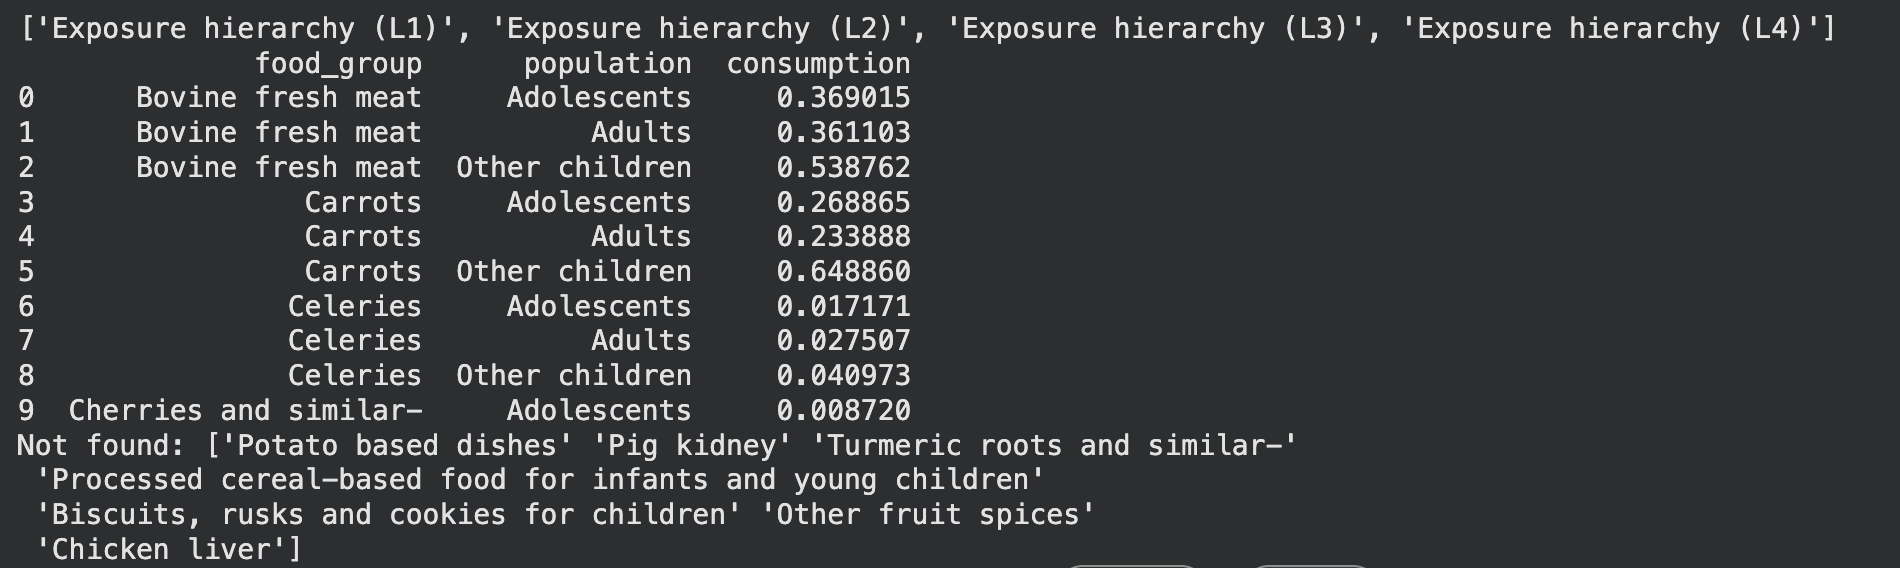

**Interpretation of Findings: food groups without consumption data**

7 of the 29 food groups have no consumption data in the Belgian 2014 survey.

**Possible reasons:**
- nobody ate them
- made for infants and young children who were not surveyed
- Belgian surveys do not report certain spices (turmeric, paprika)
- certain foods such as French fries were probably recorded as their ingredients.

**Handling: <font color="red">These groups stay in the network as food nodes without consumption edges</font>**, so for now they contribute nothing to exposure. This mainly underestimates exposure from French fries, a major source of acrylamide. Mapping fries to "Potatoes" is not an option, as it would apply the acrylamide levels of fries to every potato eaten.

# 3. Raw Network

**Step 3.1:** Occurrence edges (contaminant → food group)

This step builds the left half of the network. The network has three layers: contaminants, food groups and population groups. The consumption edges from the previous chapter connect food groups to population groups. The occurrence edges now connect contaminants to the same food groups, so every path from a contaminant through a food group to a population group can later be turned into an exposure.

- **Shared food nodes:** Every result gets the FoodEx2 Level 4 group of its food (`food_group`), so occurrence and consumption data meet in the same nodes. Foods in the same group, such as herrings and European sardines, are merged.
- **One edge per pair:** All results for one contaminant in one food group are combined into one edge with three attributes: the number of results, the number of measured values and the mean concentration in mg/kg.
- **Upper bound:** Results below the LOQ enter the mean with their LOQ, so the mean concentration is an upper bound.
- **How much is known:** `share_measured` shows how much of each edge rests on real measurements. Edges with a low share, and pairs without any edge, are where the network is least certain.

In [78]:
# set_index() makes the food name the row label, so map() can look names up
group_lookup = food_table.set_index("food")

# the Level 4 group of each food
group_lookup = group_lookup["group_L4"]

# map() adds the Level 4 group to every result
occurrence["food_group"] = occurrence["food"].map(group_lookup)

# groupby() + agg() summarise all results per contaminant and food group:
# number of results, number of measured values and mean concentration (results below the LOQ count with their LOQ)
occurrence_edges = occurrence.groupby(["substance", "food_group"]).agg(results=("measured", "count"), measured=("measured", "sum"), mean_mgkg=("value_mgkg", "mean"))

# reset_index() turns the group labels back into normal columns
occurrence_edges = occurrence_edges.reset_index()

# share of measured values per edge
occurrence_edges["share_measured"] = occurrence_edges["measured"] / occurrence_edges["results"]
print(occurrence_edges.head(10))

      substance                                                  food_group  results  measured  mean_mgkg  share_measured
0    Acrylamide                    Biscuits, rusks and cookies for children       18         5   0.037050        0.277778
1    Acrylamide                                                Chips/crisps       25        24   0.362524        0.960000
2    Acrylamide                                         Potato based dishes       45        41   0.253724        0.911111
3    Acrylamide  Processed cereal-based food for infants and young children       11         4   0.052264        0.363636
4  Aflatoxin B1                    Biscuits, rusks and cookies for children        3         0   0.000040        0.000000
5  Aflatoxin B1                                          Other fruit spices       10         0   0.002000        0.000000
6  Aflatoxin B1                                     Pistachios and similar-       38         1   0.001221        0.026316
7  Aflatoxin B1  Process

**Step 3.2:** Nodes
- Each layer of the network gets its own node table: **<font color="red">the 8 contaminants with their EFSA reference value per day and whether exposure is judged as a hazard quotient (HQ) or a margin of exposure (MOE), the 29 food groups, and the 3 population groups with their number of participants.</font>**
- The food group table also shows how many selected foods each group holds (herrings and European sardines share one group) and whether consumption data exist, which is the case for 22 of the 29 groups.
- **Used risk metrics are:**
  - HQ (hazard quotient) = exposure / tolerable intake (TWI, TDI), values above 1 exceed the safe level
  - MOE (margin of exposure) = reference point (BMDL) / exposure, used where no safe intake can be set, e.g. for substances that can cause cancer; the smaller the MOE, the higher the concern

In [79]:
# unique() lists each contaminant in the occurrence table once, DataFrame() turns the list into a table
substance_names = occurrence["substance"].unique()
substance_nodes = pd.DataFrame({"substance": substance_names})

# EFSA reference values are not part of the monitoring data, so they come from the EFSA opinions (see README)
# type of reference value per contaminant
reference_type = {
    "Cadmium": "TWI",
    "Mercury (total)": "TWI",
    "PFAS (sum of 4)": "TWI",
    "Chlorate": "TDI",
    "Lead": "BMDL01",
    "Acrylamide": "BMDL10",
    "Aflatoxin B1": "BMDL10",
    "Ochratoxin A": "BMDL10",
}
# value in mg/kg bw per day, weekly values (TWI = tolerable weekly intake) divided by 7, as consumption and therefore exposure are on a daily basis
reference_value = {
    "Cadmium": 0.0025 / 7,             # TWI 2.5 µg/kg bw, EFSA 2009
    "Mercury (total)": 0.0013 / 7,     # TWI 1.3 µg/kg bw for methylmercury, EFSA 2012
    "PFAS (sum of 4)": 0.0000044 / 7,  # TWI 4.4 ng/kg bw, EFSA 2020
    "Chlorate": 0.003,                 # TDI 3 µg/kg bw per day, EFSA 2015
    "Lead": 0.0005,                    # BMDL01 0.5 µg/kg bw per day, EFSA 2010
    "Acrylamide": 0.17,                # BMDL10 0.17 mg/kg bw per day, EFSA 2015
    "Aflatoxin B1": 0.0004,            # BMDL10 0.4 µg/kg bw per day, EFSA 2020
    "Ochratoxin A": 0.0145,            # BMDL10 14.5 µg/kg bw per day, EFSA 2020
}
# map() looks up the type and the value for each contaminant
substance_nodes["reference_type"] = substance_nodes["substance"].map(reference_type)
substance_nodes["reference_value"] = substance_nodes["substance"].map(reference_value)

# condition: True for tolerable intakes (TWI, TDI), which are compared with exposure as a hazard quotient
is_tolerable_intake = substance_nodes["reference_type"].isin(["TWI", "TDI"])
# HQ (hazard quotient) = exposure / tolerable intake (TWI, TDI), values above 1 exceed the safe level
# MOE (margin of exposure) = reference point (BMDL) / exposure, used where no safe intake can be set, e.g. for substances that can cause cancer; the smaller the MOE, the higher the concern
substance_nodes["assessment"] = "MOE"
substance_nodes.loc[is_tolerable_intake, "assessment"] = "HQ"

# count how many selected foods each Level 4 group holds
food_nodes = food_table.groupby("group_L4")["food"].agg(foods="count")

# turns the group names back to normal
food_nodes = food_nodes.reset_index()

# gives column the same name as in the edge tables
food_nodes = food_nodes.rename(columns={"group_L4": "food_group"})

# food groups that have consumption data
food_nodes["has_consumption"] = food_nodes["food_group"].isin(consumption_edges["food_group"])

# the three population groups with their number of participants (see chapter 2.2)
population_nodes = subjects.rename(columns={"Population Group (L2)": "population", "Number of subjects": "participants"})

# print
print(substance_nodes)
print(food_nodes)
print(population_nodes)

         substance reference_type  reference_value assessment
0       Acrylamide         BMDL10     1.700000e-01        MOE
1          Cadmium            TWI     3.571429e-04         HQ
2             Lead         BMDL01     5.000000e-04        MOE
3         Chlorate            TDI     3.000000e-03         HQ
4     Aflatoxin B1         BMDL10     4.000000e-04        MOE
5     Ochratoxin A         BMDL10     1.450000e-02        MOE
6  Mercury (total)            TWI     1.857143e-04         HQ
7  PFAS (sum of 4)            TWI     6.285714e-07         HQ
                                                    food_group  foods  has_consumption
0                     Biscuits, rusks and cookies for children      1            False
1                                            Bovine fresh meat      1             True
2                                                      Carrots      1             True
3                                                     Celeries      1             True
4      

**Step 3.3:** How complete is the network?

Of the 232 possible pairs of contaminant and food group (8 × 29), <font color="red">only 84 have any result, and only 55 have at least one measured value. Of the 87 possible consumption edges (29 × 3), 61 exist.
The gaps show how much of the network is unknown: 148 pairs (64%) were never measured, 29 pairs are only known to lie below the LOQ, and 26 consumption edges are missing.</font> This is the gap the modelling in the next steps has to fill.

In [80]:
# every contaminant could in principle occur in every food group
possible_pairs = substance_nodes.shape[0] * food_nodes.shape[0]
print("Possible pairs:", possible_pairs)
print("Pairs with results:", occurrence_edges.shape[0])

# condition: True for pairs with at least one measured value
has_measured = occurrence_edges["measured"] > 0
print("Pairs with at least one measured value:", has_measured.sum())
print("Consumption edges:", consumption_edges.shape[0])

# possible pairs minus pairs with results
never_measured = possible_pairs - occurrence_edges.shape[0]
print("Pairs never measured:", never_measured)

# share of the possible pairs that were never analysed (%)
share_never_measured = round(never_measured / possible_pairs * 100, 1)
print("Share never measured (%):", share_never_measured)

# pairs with results, but only below the LOQ
only_censored = occurrence_edges.shape[0] - has_measured.sum()
print("Pairs with results below the LOQ only:", only_censored)

# every food group could be eaten by every population group
possible_consumption = food_nodes.shape[0] * population_nodes.shape[0]

# consumption edges that do not exist
missing_consumption = possible_consumption - consumption_edges.shape[0]
print("Missing consumption edges:", missing_consumption)

Possible pairs: 232
Pairs with results: 84
Pairs with at least one measured value: 55
Consumption edges: 61
Pairs never measured: 148
Share never measured (%): 63.8
Pairs with results below the LOQ only: 29
Missing consumption edges: 26


**Step 3.4:** Network plotting
- The network is built with NetworkX (Link: https://networkx.org/)
- The 40 nodes are added layer by layer, then the edges from the two edge tables, with occurrence edges split into those with and without a measured value and consumption edges weighted by the amount eaten.
- A multipartite layout places contaminants, food groups and population groups in three columns, with the food groups without consumption data at the bottom.

DiGraph with 40 nodes and 145 edges


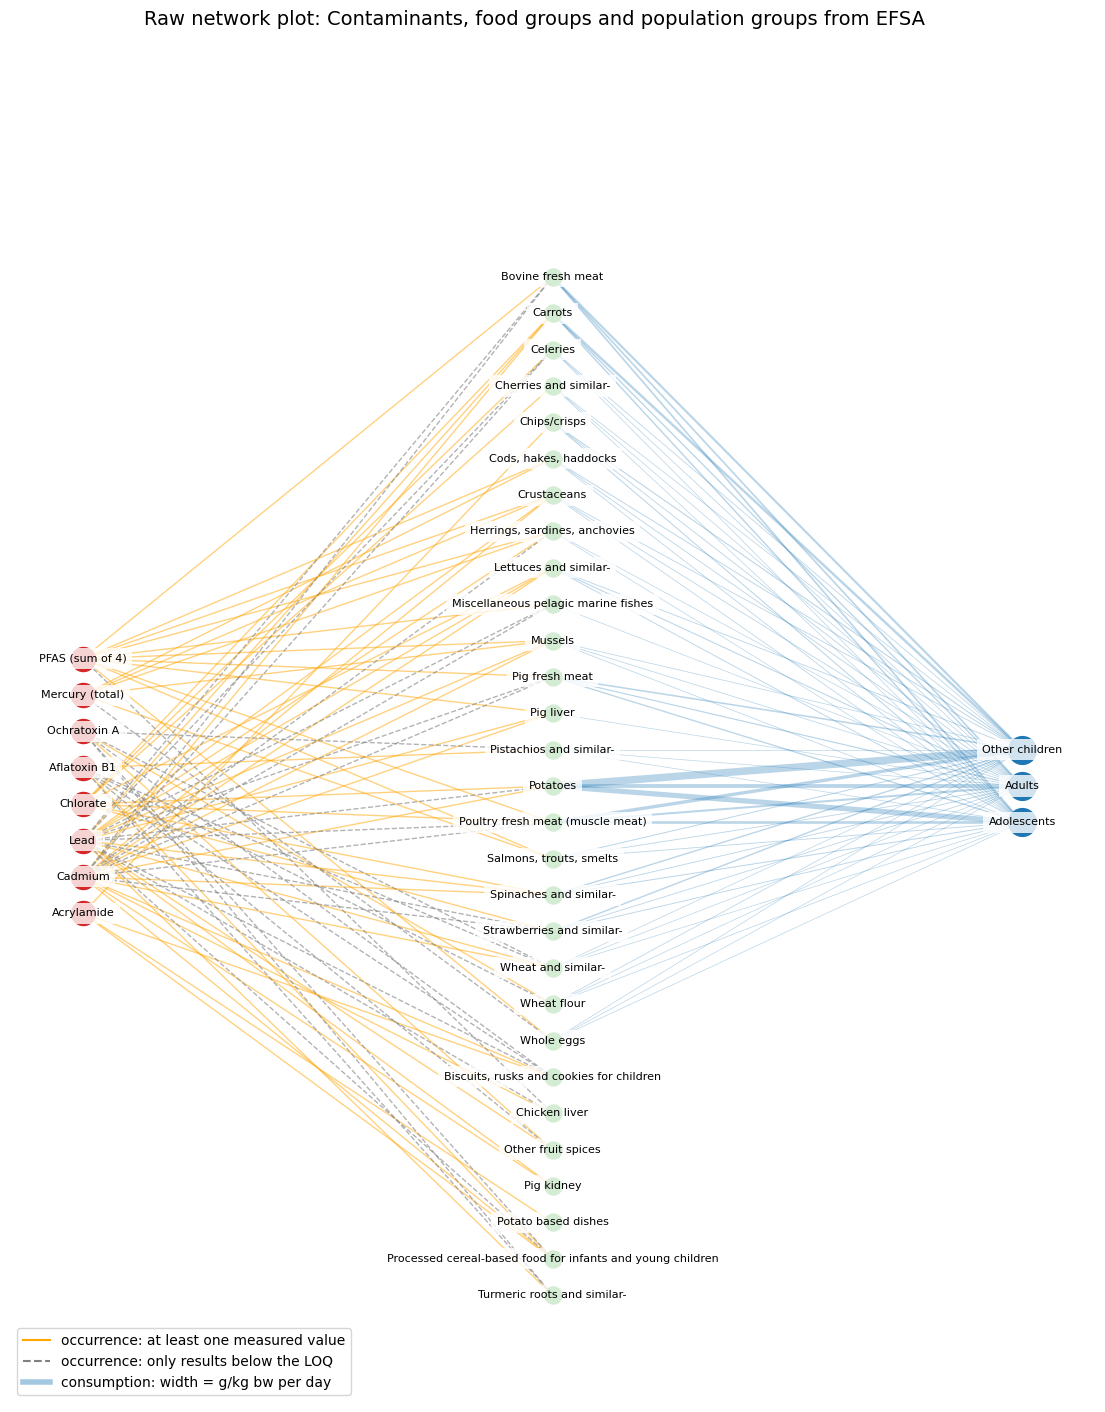

In [81]:
# sort value with nodes having no consumption data first
food_nodes = food_nodes.sort_values(["has_consumption", "food_group"], ascending=[True, False])

# the node names of each layer as plain lists (needed for network functions)
substance_list = substance_nodes["substance"].tolist()
food_list = food_nodes["food_group"].tolist()
population_list = population_nodes["population"].tolist()

# DiGraph() creates an empty network whose edges point in one direction
G = nx.DiGraph()
# add nodes for each layer
G.add_nodes_from(substance_list)
G.add_nodes_from(food_list)
G.add_nodes_from(population_list)

# add_edge() adds the occurrence edges, sorted into two lists for the plot
measured_edges = []
censored_edges = []
for index, row in occurrence_edges.iterrows():
    G.add_edge(row["substance"], row["food_group"])
    if row["measured"] > 0:
        measured_edges.append((row["substance"], row["food_group"]))
    else:
        censored_edges.append((row["substance"], row["food_group"]))

# add_edge() adds the consumption edges, the line width grows with the amount eaten
consumption_list = []
consumption_widths = []
for index, row in consumption_edges.iterrows():
    G.add_edge(row["food_group"], row["population"])
    consumption_list.append((row["food_group"], row["population"]))
    consumption_widths.append(0.5 + 2 * row["consumption"])
print(G)

# multipartite_layout() places the three layers in three columns
layers = {0: substance_list, 1: food_list, 2: population_list}
positions = nx.multipartite_layout(G, subset_key=layers)

# figure size
plt.figure(figsize=(14, 16))
# one colour per layer
nx.draw_networkx_nodes(G, positions, nodelist=substance_list, node_color="tab:red", node_size=300)
nx.draw_networkx_nodes(G, positions, nodelist=food_list, node_color="tab:green", node_size=150)
nx.draw_networkx_nodes(G, positions, nodelist=population_list, node_color="tab:blue", node_size=400)
# solid lines: at least one measured value
# dashed lines: only results below the LOQ
nx.draw_networkx_edges(G, positions, edgelist=measured_edges, edge_color="orange", alpha=0.5, arrows=False)
nx.draw_networkx_edges(G, positions, edgelist=censored_edges, edge_color="grey", style="dashed", alpha=0.6, arrows=False)
nx.draw_networkx_edges(G, positions, edgelist=consumption_list, width=consumption_widths, edge_color="tab:blue", alpha=0.3, arrows=False)
nx.draw_networkx_labels(G, positions, font_size=8, bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8})

# legend entries
measured_line = Line2D([0], [0], color="orange", label="occurrence: at least one measured value")
censored_line = Line2D([0], [0], color="grey", linestyle="--", label="occurrence: only results below the LOQ")
consumption_line = Line2D([0], [0], color="tab:blue", linewidth=4, alpha=0.4, label="consumption: width = g/kg bw per day")
plt.legend(handles=[measured_line, censored_line, consumption_line], loc="lower left")
plt.suptitle("Raw network plot: Contaminants, food groups and population groups from EFSA", fontsize=14)
plt.axis("off")
plt.show()